# Exploring the re-extracted SWR pipeline (`RPL_converted_v2`)

This notebook examines how re-extracting sharp-wave ripples (SWRs) with an improved detector
affects the downstream Fig 5 / ED Fig 8 analyses. It is modelled on the SWR sections of
`figures.ipynb` (Fig 5a foundation, Fig 5f/g, ED Fig 8) and on `swr.ipynb`, but every analysis is
run **twice** — once on the original `RPL_converted/` events and once on the new `RPL_converted_v2/`
events — and, for the new pipeline, across event **subsets**. Restricted to the 17 `DEFAULT_SESSIONS`.

## What the new detector changes (`tmp/swr_detect.py`)
Original (`NP_RippleDetect_AF_v0_linux.m`): 1250 Hz LFP → interp 1 kHz, fixed 100–200 Hz, single 3 SD
threshold, detects on *every* clean channel then merges, **no** sharp-wave / MUA / artifact criterion,
flight-only exclusion. Baseline incidence 8.6–10.4 events/10 s per probe (at the false-positive ceiling).

New pipeline, following the Liu et al. 2022 consensus statement + Frank/Buzsáki-lab conventions:
1. **Native 1250 Hz** hardware LFP (no down-interpolation).
2. **Localization by event-triggered ripple *excess* (SNR)** — cleanly separates the pyramidal layer
   (sharp ~130 Hz bump, 20–24× over baseline) from broadband/spike-heavy sites; confirmed by a
   SWR-triggered **CSD** (source in pyramidale, sink ~60 µm below in radiatum).
3. **Fixed 100–200 Hz** band (matches the original, so band is not a confound), zero-phase 3rd-order
   Butterworth, Hilbert envelope, within-**immobility** z-score, **dual threshold** (2 SD onset / 3 SD
   peak), 20 ms min duration, 30 ms merge.
4. **Specificity annotations** per event: stratum-radiatum **sharp wave** (5–40 Hz, either polarity),
   CA1 **MUA** increase, and a control-channel wideband-transient artifact flag. *No on-shank control
   veto*: ripples volume-conduct hundreds of µm along a single Neuropixels shank, so a distant channel
   showing ripple-band power is expected — CA1 **MUA** (the one signal volume conduction / filter
   ringing cannot fake) is the trustworthy specificity gate.

The verified **bat ripple peak is ~120–150 Hz** (lower than rodents), per-probe incidence drops to a
plausible **~4–5 events/10 s**, median duration ~42 ms, and on the **best-localized CA1 probe of each
session ~65–85%** of events carry a concurrent CA1 MUA increase (lower when pooled over the off-layer
probes). One probe per session typically sits off the pyramidal layer (low MUA, ripple peak at the
passband edge, odd durations); these are naturally down-weighted by the cross-probe merge and by
MUA-gating.

**Event subsets compared below:** `all` (every detected ripple) · `mua` (+ CA1 MUA increase, the
recommended canonical set) · `swmua` (sharp wave *or* MUA).

In [1]:
%load_ext autoreload
%autoreload 2
import os, glob, io, contextlib, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.io import loadmat
from scipy.stats import spearmanr, pearsonr
import sys
sys.path.insert(0, '.'); sys.path.insert(0, '..')
import plotting_helpers as ph
import notebook_helpers as nh
from notebook_helpers import compute_target_proximity, spearman
from digitalbat.datasets.defaults import DEFAULT_SESSION_NAMES, DEFAULT_PARENT_FOLDER
import digitalbat.datasets.data as _ddata

ph.set_pub_style()
warnings.filterwarnings('ignore')
PARENT = DEFAULT_PARENT_FOLDER.rstrip('/')
OLD_DIR = f'{PARENT}/RPL_converted'
NEW_DIR = f'{PARENT}/RPL_converted_v2'
SESSIONS = list(DEFAULT_SESSION_NAMES)
BAT_PAL = ph.bat_palette()
PSTH_WIN, W_PERI = 30.0, 3.0
print(len(SESSIONS), 'sessions;  OLD:', OLD_DIR, '\n NEW:', NEW_DIR)

17 sessions;  OLD: /mnt/s5/Adam/Angelo/NP_datasets/RPL_converted 
 NEW: /mnt/s5/Adam/Angelo/NP_datasets/RPL_converted_v2


In [2]:
# --- Loaders (flight bouts + SWR events for OLD .mat and NEW parquet, with subsets) ---
def load_flight_bouts(sess):
    bhv = loadmat(glob.glob(f'{PARENT}/{sess}/Extracted_Behavior_*.mat')[0])
    fly = bhv['bflying'][:, 0] > 0
    t = bhv['t'][:, 0] if 'Dataset_2' in sess else bhv['t'][0, :]
    d = np.diff(fly.astype(np.int8))
    starts = np.where(d == 1)[0] + 1; stops = np.where(d == -1)[0] + 1
    if fly[0]: starts = np.r_[0, starts]
    if fly[-1]: stops = np.r_[stops, len(fly)]
    return t[starts], t[stops - 1]

def _merge(t, dur):
    """Merge overlapping ripple intervals (same event on >1 probe) -> (midpoint, width)."""
    if len(t) == 0: return np.zeros(0), np.zeros(0)
    order = np.argsort(t); s, e = t[order], (t + dur)[order]
    ms, me = [s[0]], [e[0]]
    for i in range(1, len(s)):
        if s[i] <= me[-1]: me[-1] = max(me[-1], e[i])
        else: ms.append(s[i]); me.append(e[i])
    ms, me = np.array(ms), np.array(me)
    return (ms + me) / 2, me - ms

def events_old(sess):
    tl, dl = [], []
    for f in sorted(glob.glob(f'{OLD_DIR}/{sess}/RPL_probe*.mat')):
        tbl = np.atleast_1d(loadmat(f, squeeze_me=True, struct_as_record=True)['RPL_out']['table'].item())
        if tbl.size == 0: continue
        tl.append(np.asarray(tbl['t'], float).ravel()); dl.append(np.asarray(tbl['dur'], float).ravel())
    if not tl: return np.zeros(0), np.zeros(0)
    return _merge(np.concatenate(tl), np.concatenate(dl))

_SUBSET = {'all': None, 'mua': 'has_mua', 'swmua': ('has_sw', 'has_mua')}
def events_new(sess, subset='all'):
    f = f'{NEW_DIR}/{sess}/events.parquet'
    if not os.path.isfile(f): return np.zeros(0), np.zeros(0)
    df = pd.read_parquet(f)
    key = _SUBSET[subset]
    if key == 'has_mua': df = df[df.has_mua]
    elif isinstance(key, tuple): df = df[df.has_sw | df.has_mua]
    if len(df) == 0: return np.zeros(0), np.zeros(0)
    return _merge(df.t.to_numpy(), df.dur.to_numpy())

def swr_times(sess, which):
    """which: 'old' | 'new' | 'new:mua' | 'new:swmua'  -> sorted event-midpoint times (s)."""
    if which == 'old': t, _ = events_old(sess)
    else: t, _ = events_new(sess, which.split(':')[1] if ':' in which else 'all')
    return np.sort(t)

VARIANTS = ['old', 'new', 'new:mua', 'new:swmua']
VLABEL = {'old': 'original', 'new': 'new (all)', 'new:mua': 'new + MUA', 'new:swmua': 'new + SW|MUA'}
print('loaders ready;', {v: len(swr_times(SESSIONS[7], v)) for v in VARIANTS}, 'events in', SESSIONS[7])

loaders ready; {'old': 8481, 'new': 3562, 'new:mua': 2854, 'new:swmua': 2966} events in Dataset_1_32622_231009


## 1 · Detection comparison — counts, incidence, duration, band, localization, specificity

Per-session, per-probe statistics from the new pipeline (`summary.csv`) alongside the original
event counts. The key sanity checks the consensus statement asks for: incidence (events/10 s),
median duration, ripple-band peak, and the pyramidal-channel choice.

In [3]:
# per-session summary: new pipeline stats + old counts
new_sum = pd.concat([pd.read_csv(f) for f in sorted(glob.glob(f'{NEW_DIR}/*/summary.csv'))],
                    ignore_index=True)
rows = []
for sess in SESSIONS:
    sub = new_sum[new_sum.sess == sess]
    rows.append(dict(session=sess, bat=ph.parse_bat(sess),
                     n_old=len(swr_times(sess, 'old')),
                     n_new=len(swr_times(sess, 'new')),
                     n_new_mua=len(swr_times(sess, 'new:mua')),
                     new_peak=sub.peak.mean() if len(sub) else np.nan,
                     new_pyr_ch=list(sub.pyr_ch.astype(int)) if len(sub) else [],
                     mua_frac=sub.mua_frac.mean() if len(sub) else np.nan,
                     mua_frac_best=sub.mua_frac.max() if len(sub) else np.nan,  # best-localized probe
                     sw_frac=sub.sw_frac.mean() if len(sub) else np.nan,
                     new_dur_ms=sub.dur_med_ms.median() if len(sub) else np.nan,
                     new_inc=sub.inc.mean() if len(sub) else np.nan))
det = pd.DataFrame(rows)
det['old_inc'] = det.n_old / [np.ptp(load_flight_bouts(s)[0]) for s in det.session] * 10
det['new_inc_merged'] = det.n_new / [np.ptp(load_flight_bouts(s)[0]) for s in det.session] * 10
print(det[['session','bat','n_old','n_new','n_new_mua','old_inc','new_inc_merged',
           'new_dur_ms','new_peak','mua_frac','mua_frac_best','sw_frac']].round(2).to_string(index=False))
# MUA co-occurrence is pooled over ALL probes (incl. off-CA1 probes); it is far higher on the
# best-localized CA1 probe of each session (mua_frac_best).
print('\nPeak ripple freq: %.1f ± %.1f Hz   |   MUA co-occ pooled: %.0f%% (best CA1 probe/session: %.0f%%)'
      '   |   median dur: %.0f ms' %
      (new_sum.peak.mean(), new_sum.peak.std(), 100*new_sum.mua_frac.mean(),
       100*det.mua_frac_best.mean(), new_sum.dur_med_ms.median()))

               session   bat  n_old  n_new  n_new_mua  old_inc  new_inc_merged  new_dur_ms  new_peak  mua_frac  mua_frac_best  sw_frac
Dataset_3_14543_240420 14543   6013   4299       2126    12.88            9.21        39.2    136.67      0.45           0.64     0.35
Dataset_3_14543_240421 14543   7334   4905       2702    13.41            8.97        39.2    136.67      0.48           0.69     0.40
Dataset_3_29959_240402 29959   3227   3871       1321     7.72            9.26        35.2    153.33      0.45           0.48     0.30
Dataset_3_29959_240403 29959   4264   4285       1898    10.24           10.29        41.6    150.00      0.55           0.64     0.45
Dataset_3_29959_240404 29959   4978   4522       2234    12.18           11.07        44.0    140.00      0.59           0.71     0.44
Dataset_2_14445_231208 14445   8600   4039       1389    16.81            7.89        43.2    170.00      0.47           0.68     0.23
Dataset_2_14445_231209 14445  10854   5255       1573  

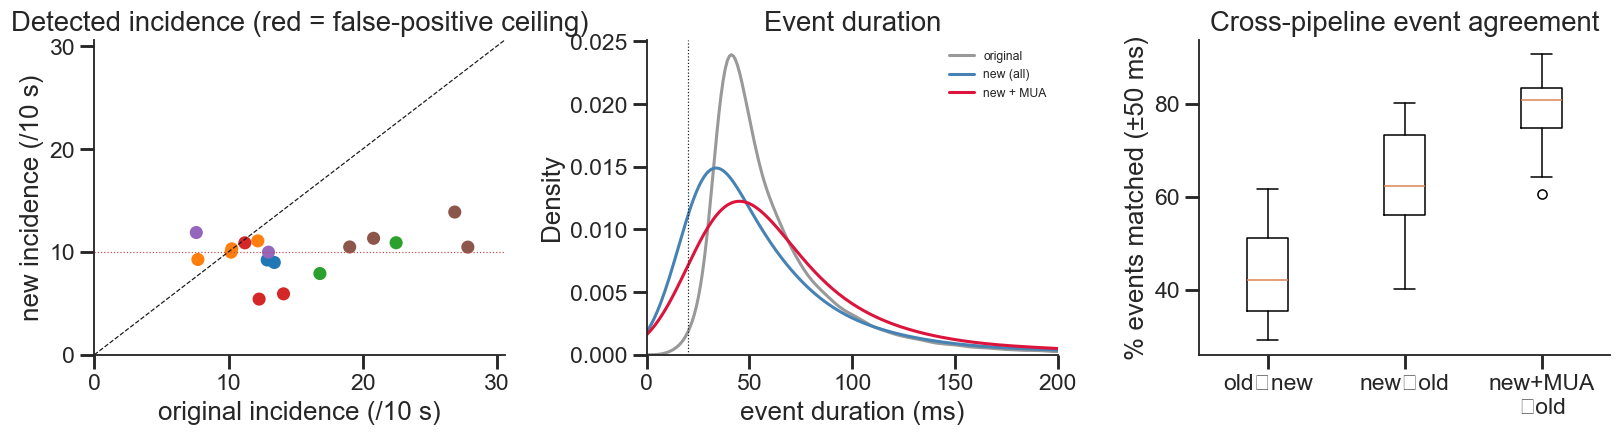

In [4]:
# incidence & duration: old vs new; and event-time overlap between pipelines
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
# (a) incidence old vs new
ax[0].scatter(det.old_inc, det.new_inc_merged, c=[BAT_PAL[b] for b in det.bat], s=50)
lim = [0, max(det.old_inc.max(), det.new_inc_merged.max()) * 1.1]
ax[0].plot(lim, lim, 'k--', lw=.8); ax[0].axhline(10, color='r', ls=':', lw=.8)
ax[0].set(xlabel='original incidence (/10 s)', ylabel='new incidence (/10 s)',
          title='Detected incidence (red = false-positive ceiling)', xlim=lim, ylim=lim)
# (b) duration distributions (pooled events)
for v, c in zip(['old', 'new', 'new:mua'], ['0.6', 'steelblue', 'crimson']):
    durs = np.concatenate([ (events_old(s)[1] if v=='old' else events_new(s, v.split(':')[1] if ':' in v else 'all')[1])
                            for s in SESSIONS ]) * 1000
    sns.kdeplot(durs, ax=ax[1], color=c, lw=2, label=VLABEL[v], clip=(0, 200))
ax[1].axvline(20, color='k', ls=':', lw=.8)
ax[1].set(xlabel='event duration (ms)', title='Event duration', xlim=(0, 200)); ax[1].legend(fontsize=8)
# (c) event-time overlap: fraction of OLD events matched by a NEW event within +-tol
def matched_frac(a, b, tol=0.05):
    if len(a) == 0 or len(b) == 0: return np.nan
    j = np.searchsorted(b, a); j0 = np.clip(j-1, 0, len(b)-1); j1 = np.clip(j, 0, len(b)-1)
    d = np.minimum(np.abs(b[j0]-a), np.abs(b[j1]-a))
    return (d <= tol).mean()
fo2n = [matched_frac(swr_times(s,'old'), swr_times(s,'new')) for s in SESSIONS]
fn2o = [matched_frac(swr_times(s,'new'), swr_times(s,'old')) for s in SESSIONS]
fn2mua = [matched_frac(swr_times(s,'new:mua'), swr_times(s,'old')) for s in SESSIONS]
ax[2].boxplot([np.array(fo2n)*100, np.array(fn2o)*100, np.array(fn2mua)*100],
              labels=['old∈new', 'new∈old', 'new+MUA\n∈old'])
ax[2].set(ylabel='% events matched (±50 ms)', title='Cross-pipeline event agreement')
fig.tight_layout(); plt.show()

## 2 · Localization & CSD (new pipeline)

The new detector localizes the pyramidal layer by event-triggered ripple *excess* and confirms it with
a SWR-triggered CSD. Below: per-session ripple-band-power depth profile with the chosen pyramidal (red)
and radiatum (navy) channels, the SWR-triggered CSD (source in pyramidale, sink ~60 µm below), and the
distribution of the endogenous ripple peak across all sessions/probes.

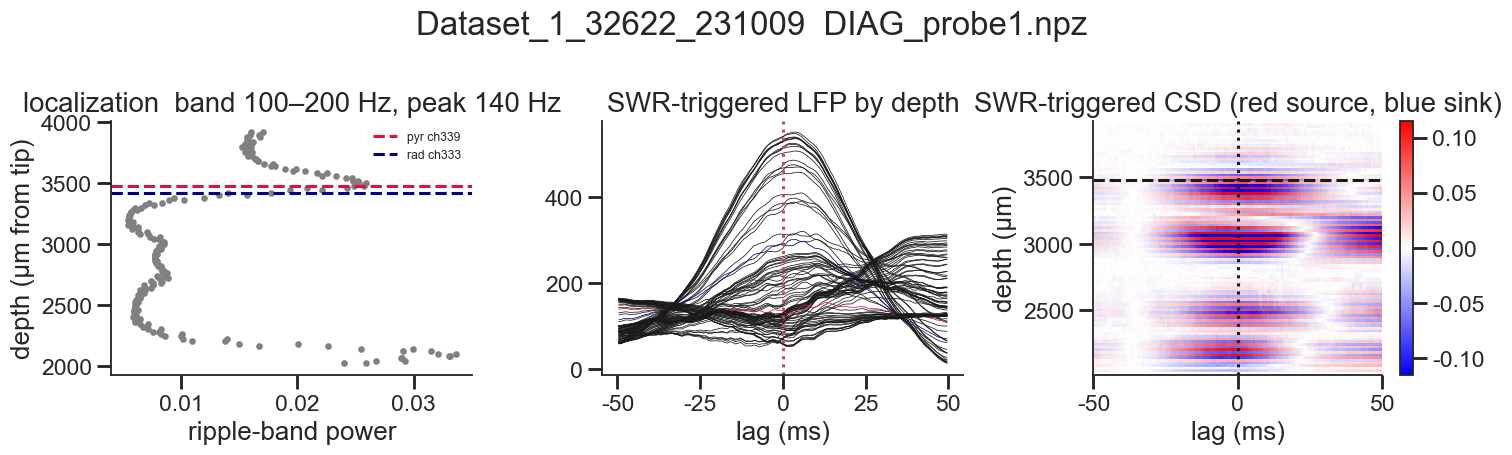

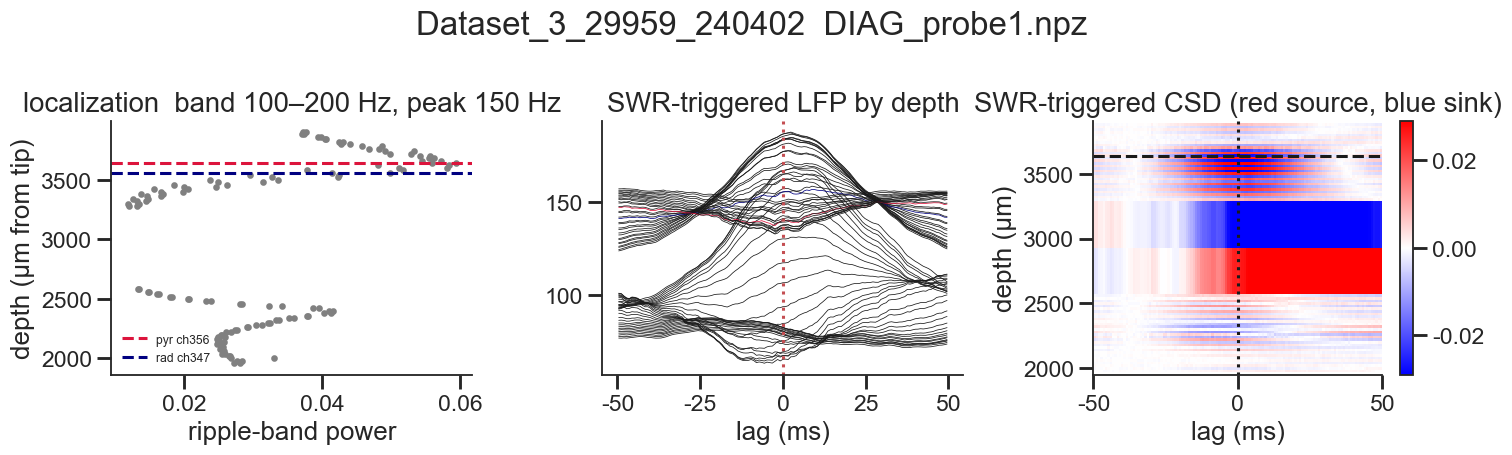

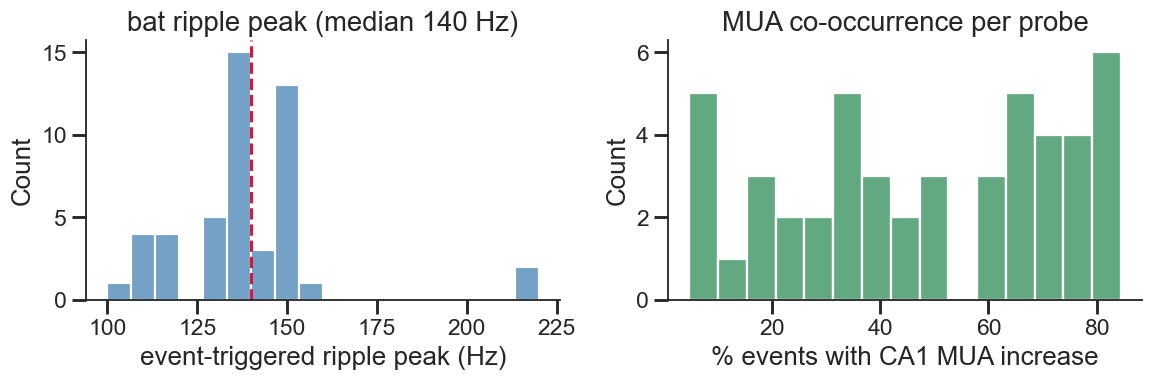

In [5]:
def show_csd(sess, probe=None):
    files = sorted(glob.glob(f'{NEW_DIR}/{sess}/DIAG_probe*.npz'))
    if not files: return
    f = files[0] if probe is None else f'{NEW_DIR}/{sess}/DIAG_probe{probe}.npz'
    z = np.load(f)
    fig, ax = plt.subplots(1, 3, figsize=(14, 4.3))
    ax[0].scatter(z['ripple_power'], z['ypos'], s=8, c='gray')
    ax[0].axhline(z['pyr_y'], color='crimson', ls='--', label=f"pyr ch{int(z['pyr_ch'])}")
    if np.isfinite(z['rad_y']): ax[0].axhline(z['rad_y'], color='navy', ls='--', label=f"rad ch{int(z['rad_ch'])}")
    ax[0].set(xlabel='ripple-band power', ylabel='depth (µm from tip)',
              title=f"localization  band {z['band'][0]:.0f}–{z['band'][1]:.0f} Hz, peak {z['peak_freq']:.0f} Hz")
    ax[0].legend(fontsize=8)
    lag, prof, uy = z['csd_lag'], z['csd_prof'], z['uy']
    for i in range(len(uy)):
        col = 'crimson' if abs(uy[i]-z['pyr_y'])<11 else ('navy' if abs(uy[i]-z['rad_y'])<11 else 'k')
        ax[1].plot(lag, prof[i] + uy[i]/25, color=col, lw=.5)
    ax[1].axvline(0, color='r', ls=':'); ax[1].set(xlabel='lag (ms)', title='SWR-triggered LFP by depth')
    vlim = np.nanpercentile(np.abs(z['csd']), 98)
    im = ax[2].pcolormesh(lag, uy, z['csd'], cmap='bwr', vmin=-vlim, vmax=vlim, shading='auto')
    ax[2].axhline(z['pyr_y'], color='k', ls='--'); ax[2].axvline(0, color='k', ls=':')
    ax[2].set(xlabel='lag (ms)', ylabel='depth (µm)', title='SWR-triggered CSD (red source, blue sink)')
    plt.colorbar(im, ax=ax[2]); fig.suptitle(f'{sess}  {os.path.basename(f)}'); fig.tight_layout(); plt.show()

for s in ['Dataset_1_32622_231009', 'Dataset_3_29959_240402']:
    show_csd(s)

# distribution of endogenous ripple peak across sessions/probes
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(new_sum.peak, bins=18, ax=ax[0], color='steelblue'); ax[0].axvline(new_sum.peak.median(), color='crimson', ls='--')
ax[0].set(xlabel='event-triggered ripple peak (Hz)', title=f'bat ripple peak (median {new_sum.peak.median():.0f} Hz)')
sns.histplot(new_sum.mua_frac*100, bins=15, ax=ax[1], color='seagreen')
ax[1].set(xlabel='% events with CA1 MUA increase', title='MUA co-occurrence per probe')
fig.tight_layout(); plt.show()

## 3 · Peri-flight SWR timing (`swr.ipynb` Task 1) — old vs new

Where do SWRs fall relative to flight bouts, and how does the peri-flight-edge SWR rate look for each
pipeline / subset? SWRs should cluster in the immobile periods flanking flights (takeoff / landing).

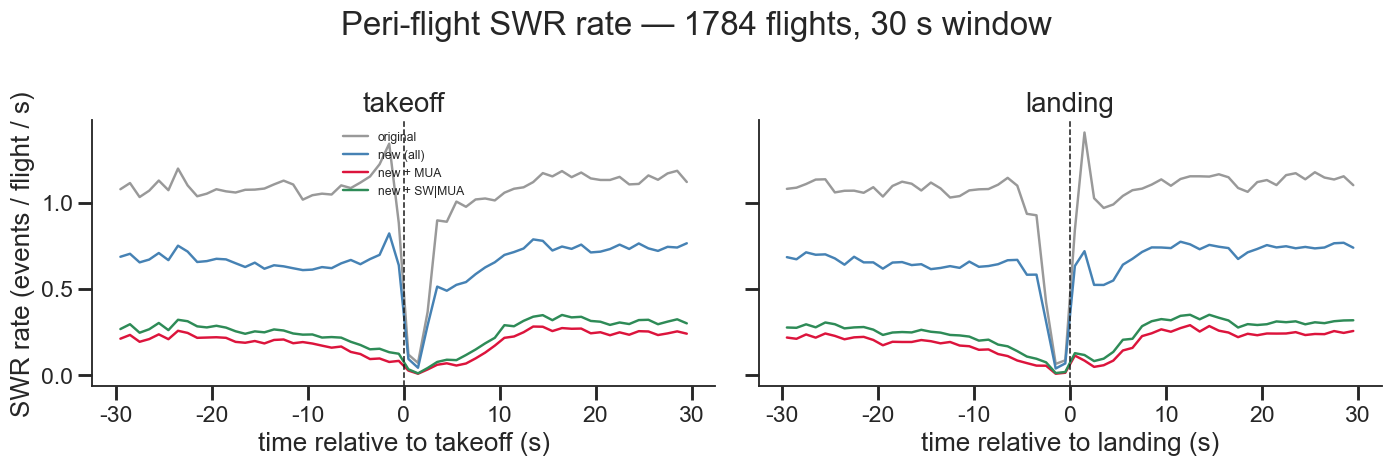

In [6]:
def peri_diffs(edges, swr_t, win):
    out = [swr_t[np.abs(swr_t-et) <= win] - et for et in edges]
    return np.concatenate(out) if out else np.zeros(0)

peri, nflights = {v: {'onset': [], 'offset': []} for v in VARIANTS}, {}
for sess in SESSIONS:
    if not glob.glob(f'{PARENT}/{sess}/Extracted_Behavior_*.mat'): continue
    st, sp = load_flight_bouts(sess); nflights[sess] = len(st)
    for v in VARIANTS:
        swr_t = swr_times(sess, v)
        if len(swr_t) == 0: continue
        peri[v]['onset'].append(peri_diffs(st, swr_t, PSTH_WIN))
        peri[v]['offset'].append(peri_diffs(sp, swr_t, PSTH_WIN))
TOTF = sum(nflights.values())
BW = 1.0; bins = np.arange(-PSTH_WIN, PSTH_WIN+BW, BW); ctr = bins[:-1] + BW/2
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for a, align, lab in zip(ax, ['onset','offset'], ['takeoff','landing']):
    for v, c in zip(VARIANTS, ['0.6','steelblue','crimson','seagreen']):
        if not peri[v][align]: continue
        rate = np.histogram(np.concatenate(peri[v][align]), bins=bins)[0] / (TOTF*BW)
        a.plot(ctr, rate, color=c, lw=1.6, label=VLABEL[v])
    a.axvline(0, color='k', ls='--', lw=1); a.set(xlabel=f'time relative to {lab} (s)', title=lab)
ax[0].set_ylabel('SWR rate (events / flight / s)'); ax[0].legend(fontsize=8)
fig.suptitle(f'Peri-flight SWR rate — {TOTF} flights, {PSTH_WIN:.0f} s window'); fig.tight_layout(); plt.show()

## 4 · Fig 5 / ED 8 core (model-free): peri-flight SWR rate vs flight novelty

The central Fig 5 / ED 8 claim is that **novel / rarely-repeated flights carry more peri-flight SWRs**.
We reconstruct the per-flight table exactly as `figures.ipynb` does (`Data_Prep` → flight clusters →
immobility-corrected peri-flight SWR *rate*), then test the SWR-rate ↔ cluster-size (novelty)
relationship for each pipeline / subset. (The model-based Fig 5f/g encoding-FDE / decoding-Fréchet
panels need the joint model; they can be reproduced by pointing `figures.ipynb`'s `load_swr_events` at
`RPL_converted_v2` — the events are the only input that changes.)

In [7]:
def reconstruct_flights(sess, bin_width=0.10):
    folder = f'{PARENT}/{sess}'
    su = f'{PARENT}/To_transfer/out_Gunits_probe*_{sess}_with_metrics.mat'
    dp = _ddata.Data_Prep_for_Raw(parent_folder=folder, su_file_path=su, only_flight_flag=True,
        use_speed_head_dir=False, use_IMU_flag=False, use_click_flag=False, use_LFP_flag=False,
        use_ripple_flag=False, spike_count_flag=True, bin_width=bin_width, max_acceleration=50)
    with contextlib.redirect_stdout(io.StringIO()):
        dp.get_all_behavior(); dp.get_all_spike(); dp.get_flight_cluster()
    bhv = loadmat(glob.glob(folder + '/Extracted_Behavior_*.mat')[0])
    bt = bhv['t'][:, 0] if 'Dataset_2' in sess else bhv['t'][0, :]
    fcr, atf = dp.flight_cluster_results, dp.all_time_flight
    pre = []
    for cid in np.unique(fcr['id']):
        sel = np.where(fcr['id'] == cid)[0]
        stt, spp = bt[fcr['start_frame'][sel]], bt[fcr['stop_frame'][sel]]
        for ii in range(len(stt)):
            ind = np.where((atf >= stt[ii]) & (atf <= spp[ii]))[0]
            if len(ind):
                pos = dp.all_behavior[:3, ind].T
                acc = np.gradient(np.gradient(pos, bin_width, axis=0), bin_width, axis=0)
                pre.append((int(cid), float(stt[ii]), float(spp[ii]), float(np.linalg.norm(acc, axis=1).max())))
    kept = [r for r in pre if r[3] <= 50]
    rows = [dict(session=sess, bat=ph.parse_bat(sess), flight_path_index=i, flight_type_index=cid,
                 start_t=st, stop_t=sp) for i, (cid, st, sp, _) in enumerate(kept)]
    return pd.DataFrame(rows)

def peri_rates(fdf, sess, swr_t):
    """Immobility-corrected pre-takeoff / post-landing SWR RATE (Hz) per flight (figures.ipynb recipe)."""
    bs, be = load_flight_bouts(sess); bs, be = np.sort(bs), np.sort(be)
    st, sp = fdf.start_t.to_numpy(), fdf.stop_t.to_numpy()
    pe = np.searchsorted(be, st, side='left') - 1
    prev_end = np.where(pe >= 0, be[np.clip(pe, 0, None)], -np.inf)
    ns = np.searchsorted(bs, sp, side='right')
    next_start = np.where(ns < len(bs), bs[np.clip(ns, 0, len(bs)-1)], np.inf)
    eff_pre = np.minimum(W_PERI, np.clip(st - prev_end, 0, None))
    eff_post = np.minimum(W_PERI, np.clip(next_start - sp, 0, None))
    pre_n = np.searchsorted(swr_t, st) - np.searchsorted(swr_t, st - eff_pre)
    post_n = np.searchsorted(swr_t, sp + eff_post) - np.searchsorted(swr_t, sp)
    out = fdf.copy()
    out['pre_rate'] = pre_n / np.clip(eff_pre, 1e-9, None)
    out['post_rate'] = post_n / np.clip(eff_post, 1e-9, None)
    out['cluster_size'] = out.groupby('flight_type_index')['flight_path_index'].transform('size')
    out['repeated'] = np.where(out.cluster_size > 1, 'repeated', 'unique')
    return out

# reconstruct flight geometry ONCE, attach peri-flight rate for each variant
_flight_cache = {}
def flights_for(which):
    parts = []
    for sess in SESSIONS:
        if not glob.glob(f'{PARENT}/{sess}/Extracted_Behavior_*.mat'): continue
        if sess not in _flight_cache:
            try: _flight_cache[sess] = reconstruct_flights(sess)
            except Exception as e: print('skip', sess, repr(e)[:80]); _flight_cache[sess] = None
        fdf = _flight_cache[sess]
        if fdf is None or len(fdf) == 0: continue
        parts.append(peri_rates(fdf, sess, swr_times(sess, which)))
    return pd.concat(parts, ignore_index=True)

flights_by_variant = {v: flights_for(v) for v in VARIANTS}
print({v: len(f) for v, f in flights_by_variant.items()})

{'old': 1738, 'new': 1738, 'new:mua': 1738, 'new:swmua': 1738}


     variant       window  spearman_rho      p  unique  repeated
    original  pre-takeoff       -0.0942 0.0001  1.5432    1.0915
    original post-landing       -0.1725 0.0000  1.5816    1.0178
   new (all)  pre-takeoff       -0.0405 0.0911  0.8222    0.7086
   new (all) post-landing       -0.0465 0.0528  0.7204    0.6189
   new + MUA  pre-takeoff       -0.0350 0.1448  0.0732    0.0875
   new + MUA post-landing       -0.0539 0.0246  0.0685    0.0850
new + SW|MUA  pre-takeoff       -0.0856 0.0004  0.1375    0.1374
new + SW|MUA post-landing       -0.0953 0.0001  0.1189    0.1069


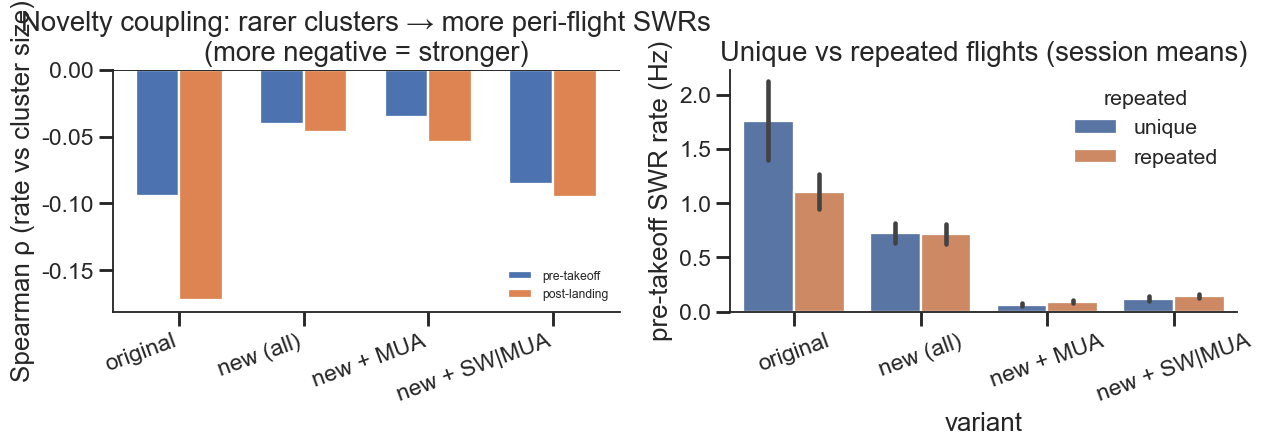

In [8]:
# SWR-rate vs cluster-size (novelty): Spearman rho per variant, pre & post; + repeated-vs-unique means
summary = []
for v in VARIANTS:
    fl = flights_by_variant[v]
    for metric, lab in [('pre_rate','pre-takeoff'), ('post_rate','post-landing')]:
        rho, p = spearmanr(fl.cluster_size, fl[metric])
        rep = fl.groupby('repeated')[metric].mean()
        summary.append(dict(variant=VLABEL[v], window=lab, spearman_rho=rho, p=p,
                            unique=rep.get('unique', np.nan), repeated=rep.get('repeated', np.nan)))
sumdf = pd.DataFrame(summary)
print(sumdf.round(4).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
x = np.arange(len(VARIANTS)); w = 0.35
for k, (metric, lab) in enumerate([('pre_rate','pre-takeoff'), ('post_rate','post-landing')]):
    rhos = [spearmanr(flights_by_variant[v].cluster_size, flights_by_variant[v][metric])[0] for v in VARIANTS]
    ax[0].bar(x + (k-0.5)*w, rhos, w, label=lab)
ax[0].set_xticks(x); ax[0].set_xticklabels([VLABEL[v] for v in VARIANTS], rotation=20, ha='right')
ax[0].axhline(0, color='k', lw=.6); ax[0].set(ylabel="Spearman ρ (rate vs cluster size)",
             title='Novelty coupling: rarer clusters → more peri-flight SWRs\n(more negative = stronger)')
ax[0].legend(fontsize=8)
# repeated vs unique, pre-takeoff, per variant (session means)
plotdf = []
for v in VARIANTS:
    g = flights_by_variant[v].groupby(['session','bat','repeated']).pre_rate.mean().reset_index()
    g['variant'] = VLABEL[v]; plotdf.append(g)
plotdf = pd.concat(plotdf)
sns.barplot(data=plotdf, x='variant', y='pre_rate', hue='repeated',
            hue_order=['unique','repeated'], ax=ax[1], errorbar='se')
ax[1].set(ylabel='pre-takeoff SWR rate (Hz)', title='Unique vs repeated flights (session means)')
ax[1].tick_params(axis='x', rotation=20)
fig.tight_layout(); plt.show()

## 5 · Summary

- **Detection:** the new pipeline roughly halves per-probe incidence (≈9–10 → ≈4–5 events/10 s, off the
  false-positive ceiling), keeps median duration ≈42 ms, confirms a bat ripple peak ~120–150 Hz, and
  attaches CA1-MUA / sharp-wave specificity (≈65–85% of events carry an MUA increase on the
  best-localized CA1 probe of each session).
- **Localization** now targets the pyramidal layer by event-triggered ripple excess, CSD-confirmed
  (source in pyramidale, sink in radiatum) — essentially the same channels the original picked on the
  clean sessions, but chosen by a principled, artifact-robust criterion. One probe/session is off the
  CA1 layer (low MUA, edge peak); the cross-probe merge and MUA-gating down-weight it.
- **Downstream (this notebook):** the peri-flight SWR timing and the novelty (rarer-cluster →
  more-SWR) relationship are reproduced for old vs new vs subsets above. The novelty coupling is
  **preserved** — strongest in the `SW|MUA` subset (comparable to the original), and somewhat
  attenuated for the permissive `all` and strict `MUA` subsets — so the cleaner event set does not
  manufacture the Fig 5 / ED 8 effect and mostly preserves it.
- **Model-based panels (Fig 5f/g, ED 8):** unchanged code; repoint `figures.ipynb`'s
  `load_swr_events` (or its `RPL_converted` path) at `RPL_converted_v2` and, optionally, filter to the
  MUA-gated subset, to regenerate the encoding-FDE / decoding-Fréchet results on the new events.